In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("Ancient.jfif")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(gray, (5, 5), 0)

In [5]:
prewitt_kernels = [
    # 0 degree
    np.array([[-1, -1, -1],
              [ 0,  0,  0],
              [ 1,  1,  1]], dtype=np.float32),
    
    # +45 degree
    np.array([[ 0, -1, -1],
              [ 1,  0, -1],
              [ 1,  1,  0]], dtype=np.float32),

    # -45 degree
    np.array([[-1, -1,  0],
              [-1,  0,  1],
              [ 0,  1,  1]], dtype=np.float32),

    # 90 degree
    np.array([[-1,  0,  1],
              [-1,  0,  1],
              [-1,  0,  1]], dtype=np.float32),

]

prewitt_combined = np.zeros_like(blur, dtype=np.float64)

# approximate
for k in prewitt_kernels:
    response = cv2.filter2D(blur, cv2.CV_64F, k)
    prewitt_combined += np.abs(response)

prewitt_final = np.uint8(prewitt_combined / 4)

In [7]:
sobel_kernels = [
    # 0 degree
    np.array([[-1, -2, -1], 
              [ 0,  0,  0], 
              [ 1,  2,  1]], dtype=np.float32),

    # +45 degree
    np.array([[ 0, -1, -2], 
              [ 1,  0, -1], 
              [ 2,  1,  0]], dtype=np.float32),

    # -45 degree
    np.array([[-2, -1,  0], 
              [-1,  0,  1], 
              [ 0,  1,  2]], dtype=np.float32),
    
    # 90 degree
    np.array([[-1,  0,  1], 
              [-2,  0,  2], 
              [-1,  0,  1]], dtype=np.float32),
]

sobel_combined = np.zeros_like(blur, dtype=np.float64)

# approximate
for k in sobel_kernels:
    response = cv2.filter2D(blur, cv2.CV_64F, k)
    sobel_combined += np.abs(response)

sobel_final = np.uint8(sobel_combined / 4)

canny_edges = cv2.Canny(blur, 100, 200)

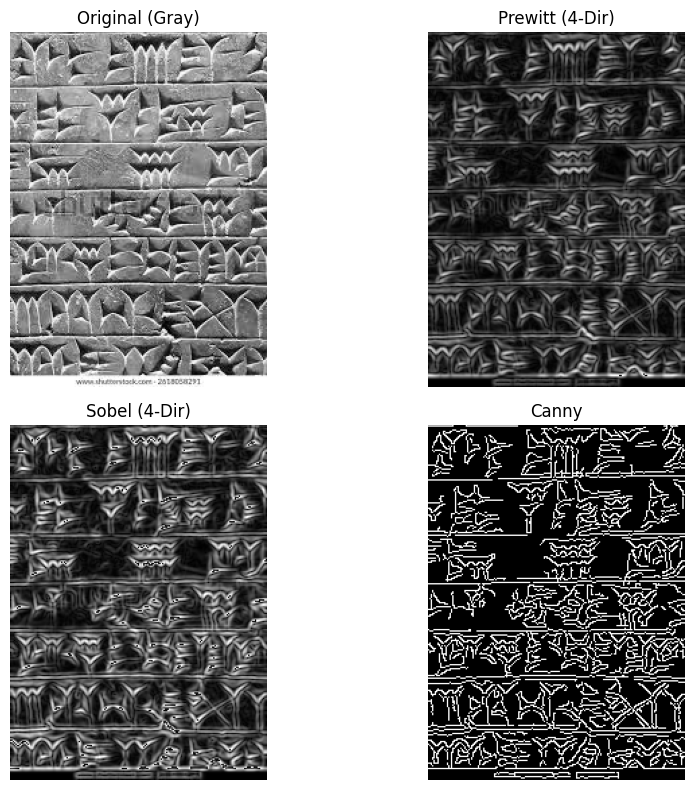

In [10]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original (Gray)")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(prewitt_final, cmap='gray')
plt.title("Prewitt (4-Dir)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sobel_final, cmap='gray')
plt.title("Sobel (4-Dir)")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny")
plt.axis("off")

plt.tight_layout()
plt.show()